# Practical 2 — Baseline model and evaluation metrics
## Hotel Booking Demand

**Assignment 4** · Aziz Abdulin · repeats the course practical on baselines and metrics on a new dataset.

Input: the clean table from Practical 1 (119,208 bookings, 34 features, time-based split).

**Plan.** 1) trivial baselines · 2) logistic regression · 3) metrics: what each one says and why accuracy misleads ·
4) confusion matrix in hotel terms · 5) ROC and precision–recall curves · 6) choosing the threshold on validation ·
7) calibration · 8) cross-validation: random vs time-based · 9) what the model learnt · 10) conclusions.

In [1]:
import json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
                             brier_score_loss, confusion_matrix, roc_curve, precision_recall_curve)

sns.set_theme(style="whitegrid", context="notebook")
DATA, FIG, RES = Path("data"), Path("figures"), Path("results")
F = json.load(open(RES / "p1_features.json"))
NUM, BIN, CAT, Y = F["num"], F["bin"], F["cat"], F["target"]
X = NUM + BIN + CAT
df = pd.read_parquet(DATA / "hotels_clean.parquet").sort_values("arrival_date", kind="stable").reset_index(drop=True)
tr, va, te = (df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test"))
y_tr, y_va, y_te = tr[Y].to_numpy(), va[Y].to_numpy(), te[Y].to_numpy()
print({k: (len(d), round(d[Y].mean(), 3)) for k, d in [("train", tr), ("val", va), ("test", te)]})

{'train': (78589, np.float64(0.362)), 'val': (18442, np.float64(0.365)), 'test': (22177, np.float64(0.406))}


## 1. Trivial baselines

Any model must beat two references:

* **No model** — predict the training cancellation rate for everyone (a constant). At threshold 0.5 it says "nobody
  cancels".
* **One feature** — the cancellation rate of the booking's lead-time decile, learnt on train. Practical 1 showed
  lead time is the strongest single signal.

In [2]:
def scores(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "F1": f1_score(y, pred), "ROC-AUC": roc_auc_score(y, p),
            "PR-AUC": average_precision_score(y, p), "Brier": brier_score_loss(y, p)}

prior = y_tr.mean()
p_none = {"val": np.full(len(va), prior), "test": np.full(len(te), prior)}
edges = np.unique(np.quantile(tr.lead_time, np.linspace(0, 1, 11)))
dec = lambda d: np.clip(np.searchsorted(edges, d.lead_time, side="right") - 1, 0, len(edges) - 2)
rate = pd.Series(y_tr).groupby(dec(tr)).mean()
p_rule = {"val": rate.reindex(dec(va)).fillna(prior).to_numpy(), "test": rate.reindex(dec(te)).fillna(prior).to_numpy()}
pd.DataFrame({"no model": scores(y_te, p_none["test"]), "lead-time decile": scores(y_te, p_rule["test"])}).T.round(3)

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC,Brier
no model,0.594,0.000,0.000,0.000,0.50,0.406,0.243
lead-time decile,0.596,0.507,0.145,0.225,0.61,0.474,0.234


"No model" already has **59 % accuracy** on the test period — 59 % of bookings are not cancelled — while finding zero
cancellations (recall 0). This is why accuracy alone is not a quality measure for an imbalanced target.

## 2. Logistic regression

Preprocessing is learnt on train only: numeric features — median imputation and standard scaling; categorical —
one-hot encoding, rare categories (< 50 bookings) merged. Two versions: plain, and with `class_weight="balanced"`
(errors on the rarer class cost more).

In [3]:
pre = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
                         ("bin", "passthrough", BIN),
                         ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), CAT)])
def logreg(**kw):
    return Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=3000, **kw))])

models, P = {}, {}
for name, kw in [("logistic regression", {}), ("logistic regression, balanced", {"class_weight": "balanced"})]:
    t = time.time(); m = logreg(**kw).fit(tr[X], y_tr)
    models[name] = m; P[name] = {"val": m.predict_proba(va[X])[:, 1], "test": m.predict_proba(te[X])[:, 1]}
    print(f"{name}: fitted in {time.time() - t:.1f} s, {m.named_steps['pre'].transform(tr[X].head(1)).shape[1]} inputs")
P["no model"], P["lead-time decile"] = p_none, p_rule
table = pd.DataFrame({k: scores(y_te, v["test"]) for k, v in P.items()}).T
table.loc[["no model", "lead-time decile", "logistic regression", "logistic regression, balanced"]].round(3)

logistic regression: fitted in 0.6 s, 97 inputs


logistic regression, balanced: fitted in 0.6 s, 97 inputs


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC,Brier
no model,0.594,0.000,0.000,0.000,0.500,0.406,0.243
lead-time decile,0.596,0.507,0.145,0.225,0.610,0.474,0.234
logistic regression,0.750,0.783,0.530,0.632,0.849,0.806,0.162
"logistic regression, balanced",0.767,0.732,0.672,0.700,0.848,0.803,0.155


## 3. What each metric says

| Metric | Question it answers | Here |
|---|---|---|
| Accuracy | share of correct answers | dominated by the majority class |
| Precision | of bookings flagged as "will cancel", how many did | cost of false alarms |
| Recall | of all cancellations, how many were flagged | cost of missed cancellations |
| F1 | harmonic mean of precision and recall at one threshold | one number for a chosen threshold |
| ROC-AUC | probability that a cancelled booking gets a higher score than a kept one | ranking quality, independent of threshold and class balance |
| PR-AUC | average precision over all thresholds; random level = cancellation rate (0.41 on test) | ranking quality focused on the positive class |
| Brier | mean squared error of the probability | are the probabilities honest |

## 4. Confusion matrix in hotel terms

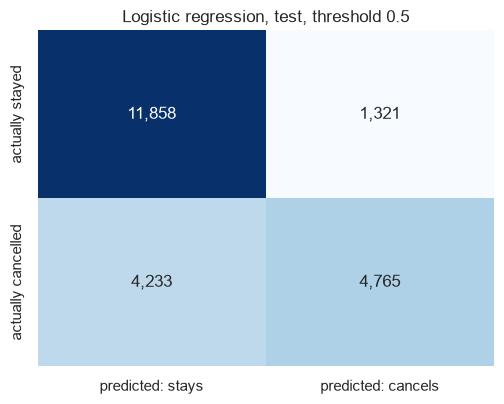

false alarms (guest came although predicted to cancel): 1,321; missed cancellations: 4,233


In [4]:
p = P["logistic regression"]["test"]
cm = confusion_matrix(y_te, (p >= 0.5).astype(int))
fig, ax = plt.subplots(figsize=(5.2, 4.2))
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["predicted: stays", "predicted: cancels"], yticklabels=["actually stayed", "actually cancelled"])
ax.set_title("Logistic regression, test, threshold 0.5"); plt.tight_layout(); plt.savefig(FIG / "p2_confusion.png", dpi=120); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"false alarms (guest came although predicted to cancel): {fp:,}; missed cancellations: {fn:,}")

If the hotel overbooks one room for every predicted cancellation, a **false alarm** means a guest arrives and has no
room (relocation and compensation), and a **missed cancellation** means an empty room (lost revenue). The two errors
have different prices — the threshold should reflect that (§6).

## 5. ROC and precision–recall curves (test)

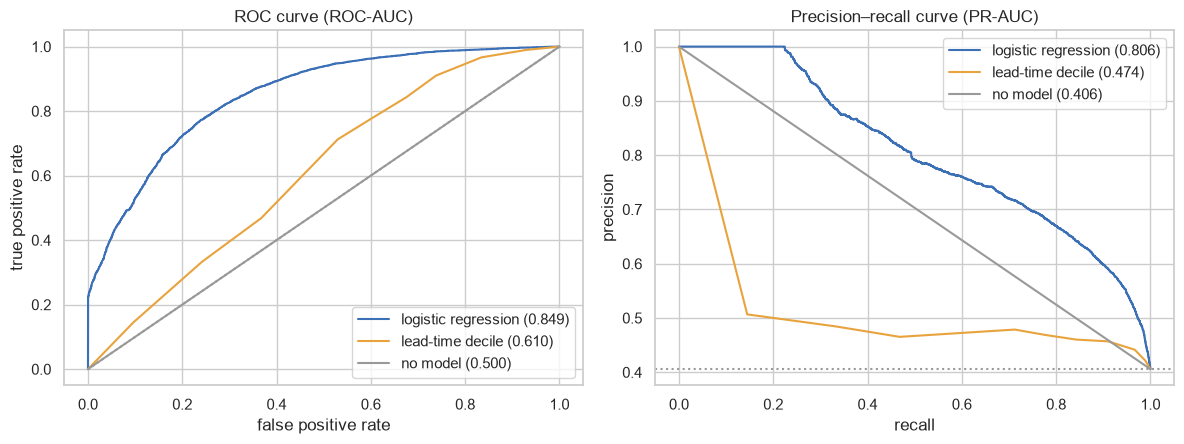

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for name, c in [("logistic regression", "#3b6fb6"), ("lead-time decile", "#e8a33d"), ("no model", "#999999")]:
    f, t, _ = roc_curve(y_te, P[name]["test"]); ax[0].plot(f, t, color=c, label=f"{name} ({roc_auc_score(y_te, P[name]['test']):.3f})")
    pr, rc, _ = precision_recall_curve(y_te, P[name]["test"]); ax[1].plot(rc, pr, color=c, label=f"{name} ({average_precision_score(y_te, P[name]['test']):.3f})")
ax[0].plot([0, 1], [0, 1], ":", color="#999"); ax[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve (ROC-AUC)")
ax[1].axhline(y_te.mean(), ls=":", color="#999"); ax[1].set(xlabel="recall", ylabel="precision", title="Precision–recall curve (PR-AUC)")
for a in ax: a.legend(loc="lower right" if a is ax[0] else "upper right")
plt.tight_layout(); plt.savefig(FIG / "p2_curves.png", dpi=120); plt.show()

## 6. Choosing the threshold on validation

0.5 is a convention, not a law. The threshold is chosen **on validation** and then applied unchanged to test. Two
rules: maximum F1, and minimum expected cost if a false alarm costs twice as much as a missed cancellation
(relocating a guest is worse than an empty room).

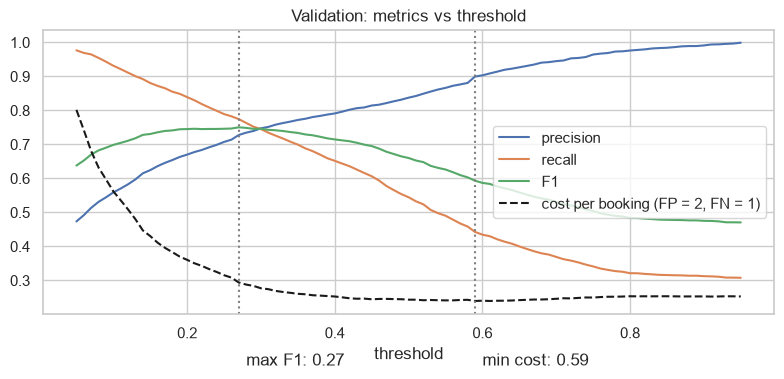

,precision,recall,F1,cost
default (0.50),0.783,0.530,0.632,0.310
max F1 on val (0.27),0.681,0.782,0.728,0.386
min cost on val (0.59),0.845,0.418,0.559,0.298


In [6]:
pv, pt = P["logistic regression"]["val"], P["logistic regression"]["test"]
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
cost = lambda y, p, t: (2 * ((p >= t) & (y == 0)).sum() + ((p < t) & (y == 1)).sum()) / len(y)
curve = pd.DataFrame([{"threshold": t, "precision": precision_score(y_va, pv >= t, zero_division=0), "recall": recall_score(y_va, pv >= t),
                       "F1": f1_score(y_va, pv >= t), "cost": cost(y_va, pv, t)} for t in grid])
t_f1, t_cost = curve.loc[curve.F1.idxmax(), "threshold"], curve.loc[curve.cost.idxmin(), "threshold"]
fig, ax = plt.subplots(figsize=(8, 4))
for c in ["precision", "recall", "F1"]: ax.plot(curve.threshold, curve[c], label=c)
ax.plot(curve.threshold, curve.cost, "--", color="k", label="cost per booking (FP = 2, FN = 1)")
for t, l in [(t_f1, "max F1"), (t_cost, "min cost")]: ax.axvline(t, ls=":", color="grey"); ax.text(t + .01, .05, f"{l}: {t:.2f}")
ax.set(xlabel="threshold", title="Validation: metrics vs threshold"); ax.legend(loc="center right"); plt.tight_layout()
plt.savefig(FIG / "p2_threshold.png", dpi=120); plt.show()
rows = {f"{l} ({t:.2f})": {**scores(y_te, pt, t), "cost": cost(y_te, pt, t)} for l, t in [("default", 0.5), ("max F1 on val", t_f1), ("min cost on val", t_cost)]}
pd.DataFrame(rows).T[["precision", "recall", "F1", "cost"]].round(3)

## 7. Calibration — can the probability be trusted?

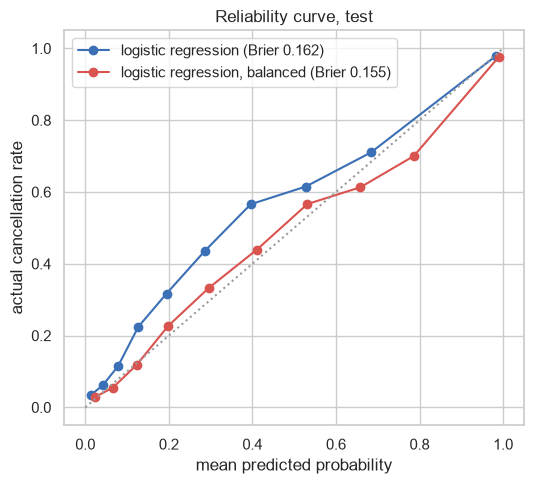

logistic regression: mean predicted — validation 0.302 (actual 0.365), test 0.333 (actual 0.406)
logistic regression, balanced: mean predicted — validation 0.367 (actual 0.365), test 0.408 (actual 0.406)


In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, c in [("logistic regression", "#3b6fb6"), ("logistic regression, balanced", "#d9534f")]:
    fr, mp = calibration_curve(y_te, P[name]["test"], n_bins=10, strategy="quantile")
    ax.plot(mp, fr, "o-", color=c, label=f"{name} (Brier {brier_score_loss(y_te, P[name]['test']):.3f})")
ax.plot([0, 1], [0, 1], ":", color="#999"); ax.set(xlabel="mean predicted probability", ylabel="actual cancellation rate", title="Reliability curve, test")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "p2_calibration.png", dpi=120); plt.show()
for name in ["logistic regression", "logistic regression, balanced"]:
    print(f"{name}: mean predicted — validation {P[name]['val'].mean():.3f} (actual {y_va.mean():.3f}), "
          f"test {P[name]['test'].mean():.3f} (actual {y_te.mean():.3f})")

The plain model **under-predicts on both later periods** (mean 0.30 vs an actual 0.37 on validation, 0.33 vs 0.41 on
test): by their features the 2017 bookings look safer than the 2015–2016 ones, yet they are cancelled as often or more —
the link between features and outcome drifted. `class_weight="balanced"` barely changes the ranking (ROC-AUC 0.848 vs
0.849); it shifts every probability up by a constant, which here happens to compensate the drift. That is luck, not a
method. The method is to recalibrate on the most recent labelled period: Platt scaling (a logistic regression on the
model's logit) fitted on validation and applied to test.

In [8]:
logit = lambda q: np.log(np.clip(q, 1e-6, 1 - 1e-6) / (1 - np.clip(q, 1e-6, 1 - 1e-6)))
platt = LogisticRegression().fit(logit(pv).reshape(-1, 1), y_va)
p_cal = platt.predict_proba(logit(pt).reshape(-1, 1))[:, 1]
P["logistic regression · Platt on val"] = {"val": platt.predict_proba(logit(pv).reshape(-1, 1))[:, 1], "test": p_cal}
pd.DataFrame({n: {"mean predicted": P[n]["test"].mean(), "actual": y_te.mean(), "Brier": brier_score_loss(y_te, P[n]["test"]),
                  "ROC-AUC": roc_auc_score(y_te, P[n]["test"])}
              for n in ["logistic regression", "logistic regression, balanced", "logistic regression · Platt on val"]}).T.round(3)

,mean predicted,actual,Brier,ROC-AUC
logistic regression,0.333,0.406,0.162,0.849
"logistic regression, balanced",0.408,0.406,0.155,0.848
logistic regression · Platt on val,0.407,0.406,0.154,0.849


## 8. Cross-validation: random folds vs time-ordered folds

Five-fold CV on the training period, two ways: random folds (shuffled bookings) and `TimeSeriesSplit` (always train on
earlier arrivals, validate on later ones). Which estimate is closer to the real score on the future test period?

In [9]:
cv = {}
for name, splitter in [("random 5-fold", KFold(5, shuffle=True, random_state=42)), ("time-ordered 5-fold", TimeSeriesSplit(5))]:
    s = cross_val_score(logreg(), tr[X], y_tr, cv=splitter, scoring="roc_auc", n_jobs=-1)
    cv[name] = {"mean ROC-AUC": s.mean(), "std": s.std(), "folds": np.round(s, 3).tolist()}
cv["real test (May–Aug 2017)"] = {"mean ROC-AUC": roc_auc_score(y_te, pt), "std": np.nan, "folds": []}
pd.DataFrame(cv).T

,mean ROC-AUC,std,folds
random 5-fold,0.906923,0.001864,"[0.904, 0.908, 0.909, 0.909, 0.906]"
time-ordered 5-fold,0.882583,0.018201,"[0.912, 0.858, 0.891, 0.872, 0.88]"
real test (May–Aug 2017),0.849128,NaN,[]


## 9. What the model learnt

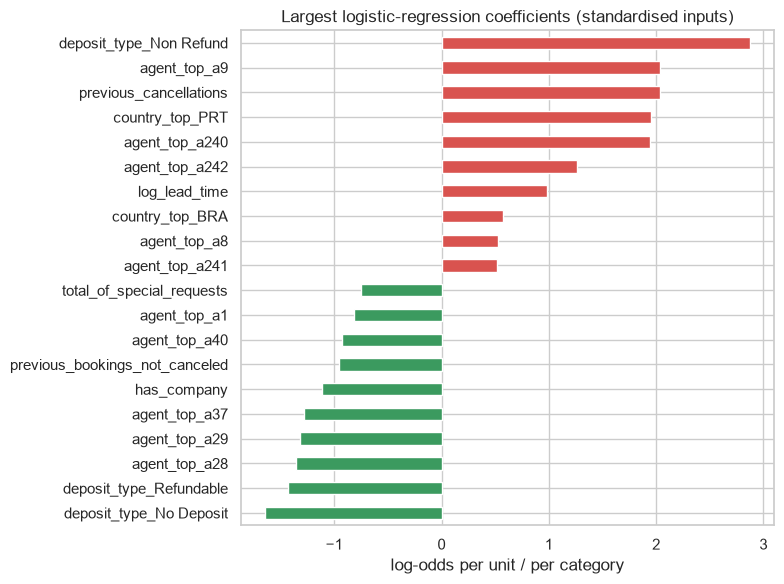

raise cancellation: {'agent_top_a240': 1.94, 'country_top_PRT': 1.95, 'previous_cancellations': 2.03, 'agent_top_a9': 2.04, 'deposit_type_Non Refund': 2.87}
lower cancellation: {'deposit_type_No Deposit': -1.64, 'deposit_type_Refundable': -1.43, 'agent_top_a28': -1.36, 'agent_top_a29': -1.31, 'agent_top_a37': -1.28}


In [10]:
m = models["logistic regression"]
names = m.named_steps["pre"].get_feature_names_out()
coef = pd.Series(m.named_steps["clf"].coef_[0], index=[n.split("__", 1)[1] for n in names]).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
pd.concat([coef.head(10), coef.tail(10)]).plot.barh(ax=ax, color=["#3b9a5f"] * 10 + ["#d9534f"] * 10)
ax.set(title="Largest logistic-regression coefficients (standardised inputs)", xlabel="log-odds per unit / per category"); plt.tight_layout()
plt.savefig(FIG / "p2_coefficients.png", dpi=120); plt.show()
print("raise cancellation:", coef.tail(5).round(2).to_dict()); print("lower cancellation:", coef.head(5).round(2).to_dict())

In [11]:
out = table.copy()
out.loc["logistic regression · threshold max F1 on val"] = scores(y_te, pt, t_f1)
out.round(4).to_csv(RES / "p2_metrics_test.csv")
json.dump({"t_f1": float(t_f1), "t_cost": float(t_cost), "cv": {k: v["mean ROC-AUC"] for k, v in cv.items()}}, open(RES / "p2_summary.json", "w"), indent=1)
out.round(3)

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC,Brier
logistic regression,0.750,0.783,0.530,0.632,0.849,0.806,0.162
"logistic regression, balanced",0.767,0.732,0.672,0.700,0.848,0.803,0.155
no model,0.594,0.000,0.000,0.000,0.500,0.406,0.243
lead-time decile,0.596,0.507,0.145,0.225,0.610,0.474,0.234
logistic regression · threshold max F1 on val,0.763,0.681,0.782,0.728,0.849,0.806,0.162


## 10. Conclusions

1. **Accuracy misleads.** Predicting "nobody cancels" scores 59.4 % accuracy on the test period while finding no
   cancellation at all. The quality of a classifier for an imbalanced target is read from recall, precision, F1 and,
   independent of the threshold, ROC-AUC and PR-AUC.
2. **The baseline is strong.** Logistic regression on the 34 prepared features reaches ROC-AUC 0.849 and PR-AUC 0.806
   on test (random level 0.406), far above the one-feature reference (lead-time decile: 0.610 / 0.474). It learnt the
   patterns seen in Practical 1: non-refundable deposits, previous cancellations, Portuguese guests and two large
   agencies raise the risk; refundable or no deposit lower it.
3. **The threshold is a business decision.** At the default 0.5 the model finds only 53 % of cancellations. The
   threshold that maximises F1 on validation (0.27) finds 78 % on test (F1 0.632 → 0.728). If a relocated guest costs
   twice an empty room, the cost-optimal threshold on validation is 0.59 and lowers the expected cost on test from 0.310
   to 0.298 per booking.
4. **Probabilities drift.** The model under-predicts in 2017 (mean 0.33 vs an actual 0.41) because the link between
   features and outcome changed. Platt scaling fitted on the most recent labelled period (validation) fixes it
   (mean 0.407, Brier 0.162 → 0.154) without touching the ranking; class weights only happened to land close.
5. **Cross-validation must respect time.** Random 5-fold CV promises ROC-AUC 0.907 ± 0.002, time-ordered CV
   0.883 ± 0.018, and the real future period gives 0.849. Shuffled folds mix group duplicates and seasons and overstate
   quality; the time-ordered estimate is closer and shows the real fold-to-fold variation.